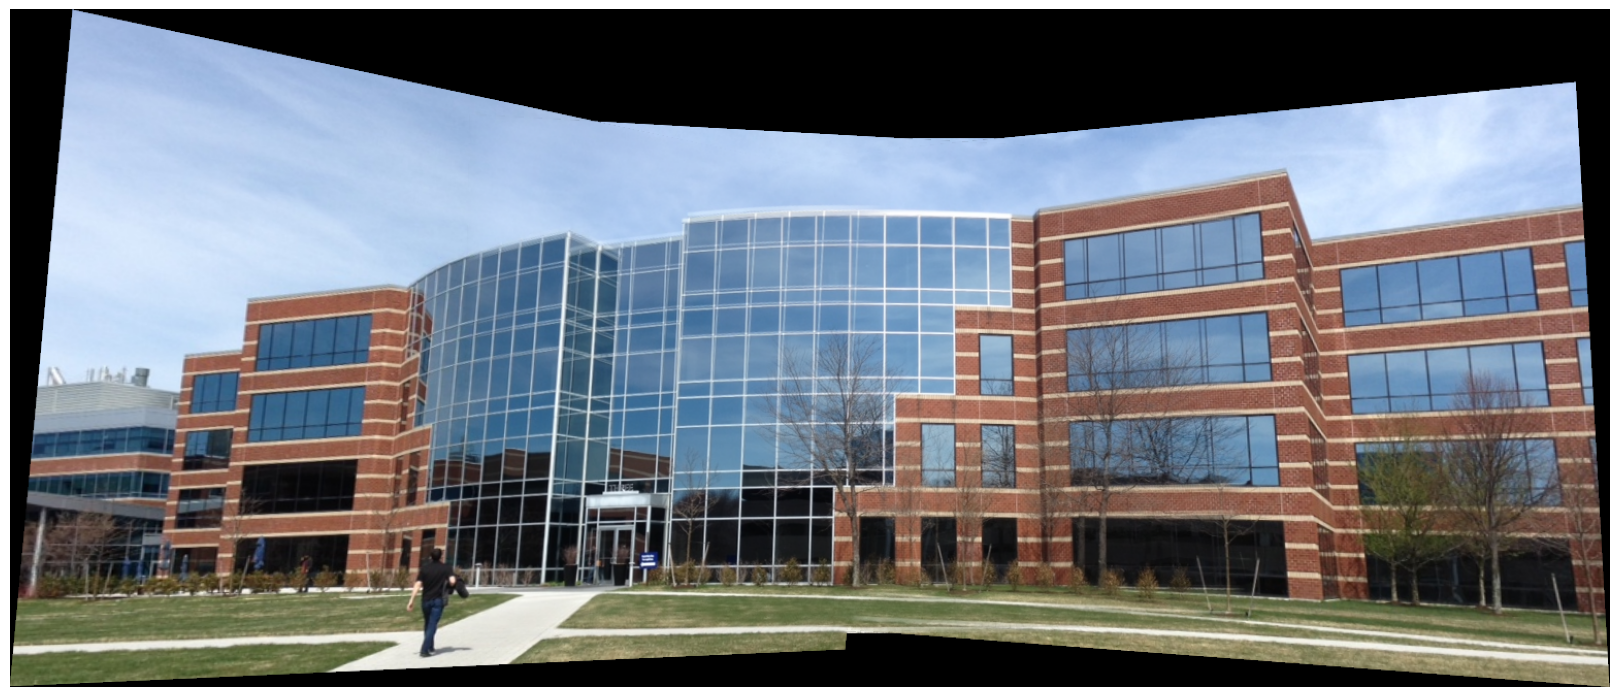

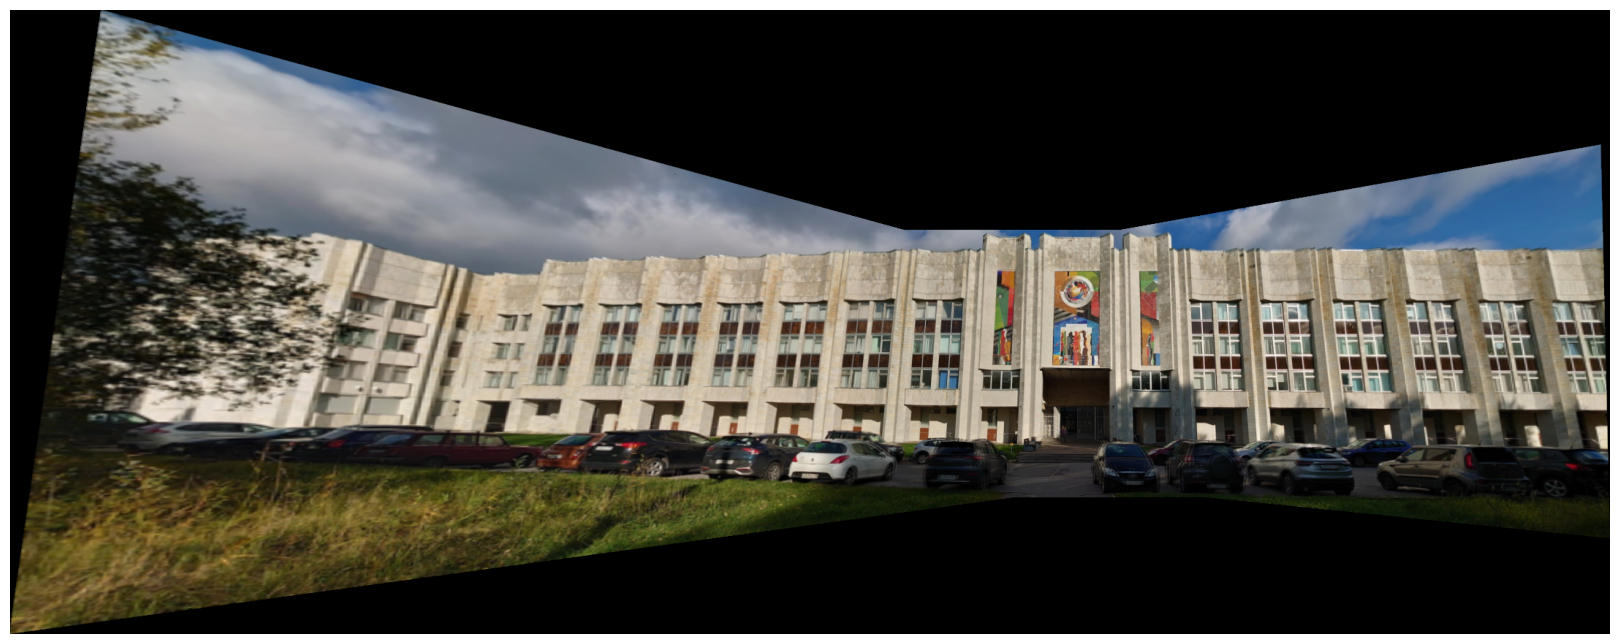

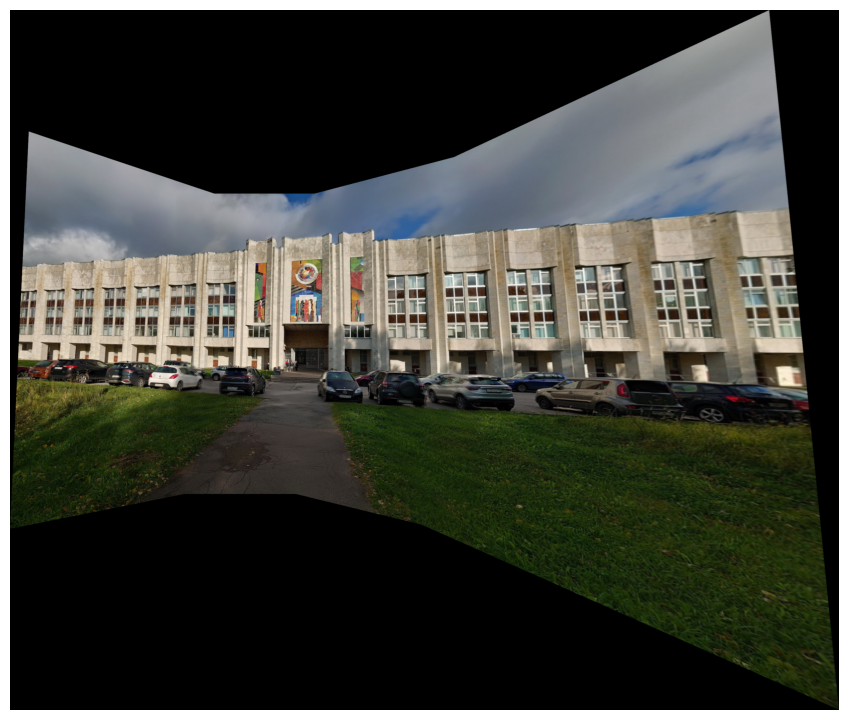

In [9]:
import os
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


DATA_DIR = Path('data')
OUTPUT_DIR = Path('panorama_results')
OUTPUT_DIR.mkdir(exist_ok=True)


def read_images(group, max_side=1000):
    paths = sorted((DATA_DIR / group).glob('*.jpg'))
    images = []
    for p in paths:
        img = cv.imread(str(p))
        k = min(1., max_side/max(img.shape[:2]))
        if k < 1: img = cv.resize(img, None, fx=k, fy=k, interpolation=cv.INTER_AREA)
        images.append(img)
    return images


def find_pair_homography(img1, img2):
    orb = cv.ORB_create(nfeatures=2000)
    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    bf = cv.BFMatcher_create(cv.NORM_HAMMING)
    matches = bf.knnMatch(des1, des2, k=2)
    good = [m for pair in matches if len(pair)==2 for m,n in [pair] if m.distance < 0.6*n.distance]

    if len(good) < 10:
        raise ValueError(f'Недостаточно совпадений: {len(good)}')
    
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    
    H, _ = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

    return H

def stitch_group(group):
    images = read_images(group, max_side=650 if group == 'building2' else 1000)
    H = [find_pair_homography(images[i], images[i+1]) for i in range(len(images)-1)]
    center = len(images)//2
    transforms = [np.eye(3) for _ in images]

    for i in range(center-1,-1,-1):
        transforms[i] = transforms[i+1] @ H[i]
    for i in range(center+1,len(images)):
        transforms[i] = transforms[i-1] @ np.linalg.inv(H[i-1])

    corners=[]
    for img,T in zip(images,transforms):
        h,w=img.shape[:2]
        pts=np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
        corners.append(cv.perspectiveTransform(pts,T).reshape(-1,2))

    all_pts=np.vstack(corners)
    left,top=np.floor(all_pts.min(axis=0)).astype(int)
    right,bottom=np.ceil(all_pts.max(axis=0)).astype(int)
    W,HH=int(right-left),int(bottom-top)
    offset=np.array([[1,0,-left],[0,1,-top],[0,0,1]],dtype=np.float64)
    accum=np.zeros((HH,W,3),np.float32)
    weights=np.zeros((HH,W),np.float32)

    for img,T in zip(images,transforms):
        h,w=img.shape[:2]
        warp=offset@T
        warped=cv.warpPerspective(img,warp,(W,HH))
        mask=cv.warpPerspective(np.ones((h,w),np.uint8)*255,warp,(W,HH),flags=cv.INTER_NEAREST)
        dist=cv.distanceTransform(mask,cv.DIST_L2,3)
        weight=np.minimum(dist,35).astype(np.float32)
        accum+=warped.astype(np.float32)*weight[:,:,None]
        weights+=weight

    result=np.uint8(np.clip(accum/np.maximum(weights[:,:,None],1e-6),0,255))
    valid=(weights>0).astype(np.uint8)
    xy=cv.findNonZero(valid)

    if xy is not None:
        x,y,w,h=cv.boundingRect(xy)
        result=result[y:y+h,x:x+w]

    out=OUTPUT_DIR/f'panorama_{group}.jpg'
    cv.imwrite(str(out), result)
    plt.figure(figsize=(16, 7))
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.axis('off')
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.show()
    return str(out)

for group in ('building1', 'building2', 'building3'):
    stitch_group(group)
